In [6]:
import os
import gdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTETomek

sns.set_theme(style="whitegrid", palette="Set2")

if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

target_dir = '/content/drive/MyDrive/N33/04 Datasets/'
os.makedirs(target_dir, exist_ok=True)
print(f" Thư mục lưu trữ dữ liệu: {target_dir}")

 Thư mục lưu trữ dữ liệu: /content/drive/MyDrive/N33/04 Datasets/


In [7]:
# 1. Tải dữ liệu gốc Breast_Cancer.csv
output_file = 'Breast_Cancer.csv'
drive_raw_path = os.path.join(target_dir, output_file)

if os.path.exists(drive_raw_path):
    df = pd.read_csv(drive_raw_path)
else:
    if not os.path.exists(output_file):
        file_id = '11v9wGSrAL3WY_pfIehGL5mVOvTBXGiIh'
        gdown.download(f'https://drive.google.com/uc?id={file_id}', output_file, quiet=False, fuzzy=True)
    df = pd.read_csv(output_file)

print("Kích thước dữ liệu gốc:", df.shape)

# 2. Xóa khoảng trắng thừa ở tên cột, giá trị chuỗi và khử trùng lặp hoàn toàn
df.columns = df.columns.str.strip()
df = df.apply(lambda s: s.str.strip() if pd.api.types.is_string_dtype(s) else s)
n_before = len(df)
df = df.drop_duplicates(keep='first').reset_index(drop=True)
print(f"Đã loại bỏ bản ghi trùng lặp: {n_before - len(df)} | Số bản ghi còn lại: {len(df)}")

# 3. Tạo biến phái sinh lâm sàng Positive_Node_Ratio (Tỷ lệ hạch dương tính)
df['Positive_Node_Ratio'] = np.where(
    df['Regional Nodes Examined'] > 0,
    df['Regional Nodes Positive'] / df['Regional Nodes Examined'],
    0.0
)

# 4. Lưu bản chia thô (raw split) trước khi mã hóa nhãn
df_train_raw, df_test_raw = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df['Status']
)
df_train_raw.to_csv(os.path.join(target_dir, 'train.csv'), index=False)
df_test_raw.to_csv(os.path.join(target_dir, 'test.csv'), index=False)

# 5. Mã hóa nhãn mục tiêu Status (Alive=0, Dead=1) & Loại bỏ biến rò rỉ tương lai 'Survival Months',
#    đồng thời loại bỏ cột 'Differentiate' vì trùng lặp 100% thông tin y khoa với cột 'Grade' (tránh VIF = vô cùng)
df['Status'] = df['Status'].map({'Alive': 0, 'Dead': 1})
x = df.drop(columns=['Status'])
y = df['Status']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

Kích thước dữ liệu gốc: (100000, 17)
Đã loại bỏ bản ghi trùng lặp: 0 | Số bản ghi còn lại: 100000


In [8]:
# Kiểm tra trùng khớp chỉ số (index) và tính độc lập giữa Train và Test
train_ids, test_ids = set(x_train.index), set(x_test.index)
assert train_ids.isdisjoint(test_ids), "PHÁT HIỆN RÒ RỈ DỮ LIỆU: Train và Test giao nhau!"
assert set(df_train_raw.index) == train_ids and set(df_test_raw.index) == test_ids, \
    "File CSV xuất ra không khớp với tập chia mô hình!"
assert df.duplicated().sum() == 0, "Vẫn còn bản ghi trùng lặp sau khi làm sạch!"

print(" Kiểm định thành công: Train/Test độc lập hoàn toàn | Không còn bản ghi trùng lặp")

# Kiểm tra các dòng có vector đặc trưng giống nhau tình cờ rơi vào 2 tập (do thiếu patient_id)
overlap = pd.merge(x_train, x_test, how='inner')
print(f"Số dòng có cùng vector đặc trưng giữa Train và Test (ghi nhận giới hạn dữ liệu): {len(overlap)}")

# Bảng phân bố tỷ lệ nhãn mục tiêu giữa Train và Test
ratio = pd.DataFrame({
    'Train set (%)': y_train.value_counts(normalize=True) * 100,
    'Test set (%)': y_test.value_counts(normalize=True) * 100
})
display(ratio.round(2))

 Kiểm định thành công: Train/Test độc lập hoàn toàn | Không còn bản ghi trùng lặp
Số dòng có cùng vector đặc trưng giữa Train và Test (ghi nhận giới hạn dữ liệu): 0


,Train set (%),Test set (%)
Status,,
0,67.54,67.54
1,32.46,32.46


In [9]:
import re
num_cols = ['Age', 'Tumor Size', 'Regional Nodes Examined', 'Regional Nodes Positive', 'Positive_Node_Ratio']
nomial_cols = ['Race', 'Marital status at diagnosis', 'A Stage', 'Estrogen Status', 'Progesterone Status']
ordinal_cols = ['T Stage', 'N Stage', '6th Stage', 'Grade']
blanks=['NA', 'Blank(s)', 'TX', 'NX', 'OCCULT', 'UNK Stage', 'Unknown']
df.replace(blanks, np.nan, inplace=True)
df.dropna(subset=ordinal_cols, inplace=True)
df['T Stage']=df['T Stage'].apply(lambda x:str(x)[:2] if str(x).startswith('T') and 'is' not in str(x) else x)
df['N Stage']=df['N Stage'].apply(lambda x:str(x)[:2] if str(x).startswith('N') else x)
df['6th Stage']=df['6th Stage'].apply(lambda x:re.sub(r'[^IV0]', '', str(x)) if isinstance(x, str) else x)
X=df.drop(columns=['Status'])
y=df['Status']
x_train, x_test, y_train, y_test=train_test_split(X, y, test_size=0.15, random_state=42, stratify=y)
ord_cats = [
    ['T0', 'Tis', 'T1', 'T2', 'T3', 'T4'],
    ['N0', 'N1', 'N2', 'N3'],
    ['0', 'I', 'II', 'III', 'IV'],
    ['I', 'II', 'III', 'IV'],
    #['T0', 'Ta', 'Tis', 'Tispu', 'Tispd', 'T1', 'T1mic', 'T1a', 'T1a1', 'T1a2', 'T1b', 'T1aNOS', 'T1b1', 'T1b2', 'T1bNOS', 'T1c', 'T1NOS', 'T2', 'T2a', 'T2b', 'T2c', 'T2NOS', 'T3', 'T3a', 'T3b', 'T3c', 'T3NOS', 'T4', 'T4a', 'T4b', 'T4c', 'T4d', 'T4NOS', 'NA', 'TX', 'Blank(s)'],
    #['N0', 'N0(i-)', 'N0(i+)', 'N0(mol-)', 'N0(mol+)', 'N1', 'N1a', 'N1b', 'N1c', 'N1mi', 'N1NOS', 'N2', 'N2a', 'N2b', 'N2c', 'N2NOS', 'N3', 'N3a', 'N3b', 'N3c', 'N3NOS', 'NA', 'NX', 'Blank(s)'],
    #['0', '0a', '0is', 'I', 'INOS', 'IA', 'IA1', 'IA2', 'IB', 'IB1', 'IB2', 'IC', 'IS', 'IEA', 'IEB', 'IE', 'ISA', 'ISB', 'II', 'IINOS', 'IIA', 'IIB', 'IIC', 'IIEA', 'IIEB', 'IIE', 'IISA', 'IISB', 'IIS', 'IIESA', 'IIESB', 'IIES', 'III', 'IIINOS', 'IIIA', 'IIIB', 'IIIC', 'IIIEA', 'IIIEB', 'IIIE', 'IIISA', 'IIISB', 'IIIS', 'IIIESA', 'IIIESB', 'IIIES', 'IV', 'IVNOS', 'IVA', 'IVB', 'IVC', 'NA', 'OCCULT', 'UNK Stage', 'Blank(s)'],
    #['I', 'II', 'III', 'IV']
]

# Kiểm tra tính hợp lệ của các thứ bậc lâm sàng
for col, cats in zip(ordinal_cols, ord_cats):
    observed = set(df[col].dropna().astype(str).unique())
    assert observed == set(cats), f"{col}: {sorted(observed)} != {cats}"
print(" Thứ bậc các biến Ordinal khớp 100% với dữ liệu lâm sàng!")

# Thiết lập ColumnTransformer:
# Dùng drop='first' trong OneHotEncoder để tránh bẫy biến giả (Dummy Variable Trap / Đa cộng tuyến) cho Hồi quy tuyến tính
preprocessor = ColumnTransformer(
    transformers=[
        ('num', PowerTransformer(method='yeo-johnson', standardize=True), num_cols),
        ('nomial', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), nomial_cols),
        ('ordinal', OrdinalEncoder(categories=ord_cats), ordinal_cols)
    ]
).set_output(transform='pandas')

#Chỉ fit_transform trên tập Train và transform trên tập Test
X_train = preprocessor.fit_transform(x_train)
X_test = preprocessor.transform(x_test)

print(f"\n✅ Số lượng đặc trưng đầu ra sau biến đổi: {X_train.shape[1]} cột\n")

feature_df = pd.DataFrame({
    'STT': range(1, len(X_train.columns) + 1),
    'Tên đặc trưng': X_train.columns,
    'Nhóm biến': [
        'Số liên tục (Yeo-Johnson)' if c.startswith('num__')
        else ('Định danh (One-Hot)' if c.startswith('nomial__')
        else 'Thứ bậc (Ordinal)')
        for c in X_train.columns
    ]
})
display(feature_df)

 Thứ bậc các biến Ordinal khớp 100% với dữ liệu lâm sàng!

✅ Số lượng đặc trưng đầu ra sau biến đổi: 28 cột



,STT,Tên đặc trưng,Nhóm biến
0,1,num__Age,Số liên tục (Yeo-Johnson)
1,2,num__Tumor Size,Số liên tục (Yeo-Johnson)
2,3,num__Regional Nodes Examined,Số liên tục (Yeo-Johnson)
3,4,num__Regional Nodes Positive,Số liên tục (Yeo-Johnson)
4,5,num__Positive_Node_Ratio,Số liên tục (Yeo-Johnson)
5,6,nomial__Race_Non-Hispanic American Indian/Alas...,Định danh (One-Hot)
6,7,nomial__Race_Non-Hispanic Asian or Pacific Isl...,Định danh (One-Hot)
7,8,nomial__Race_Non-Hispanic Black,Định danh (One-Hot)
8,9,nomial__Race_Non-Hispanic Unknown Race,Định danh (One-Hot)
9,10,nomial__Race_Non-Hispanic White,Định danh (One-Hot)


SMOTE hoàn tất
SMOTETomek hoàn tất
Trước khi cân bằng (Original Train): {0: 23837, 1: 12781} | Shape: (36618, 28)
Sau khi dùng SMOTE:                  {1: 23837, 0: 23837} | Shape: (47674, 28)
Sau khi dùng SMOTETomek:             {1: 22051, 0: 22051} | Shape: (44102, 28)
Tập Kiểm thử (Test - Giữ nguyên):    {0: 4207, 1: 2255} | Shape: (6462, 28)


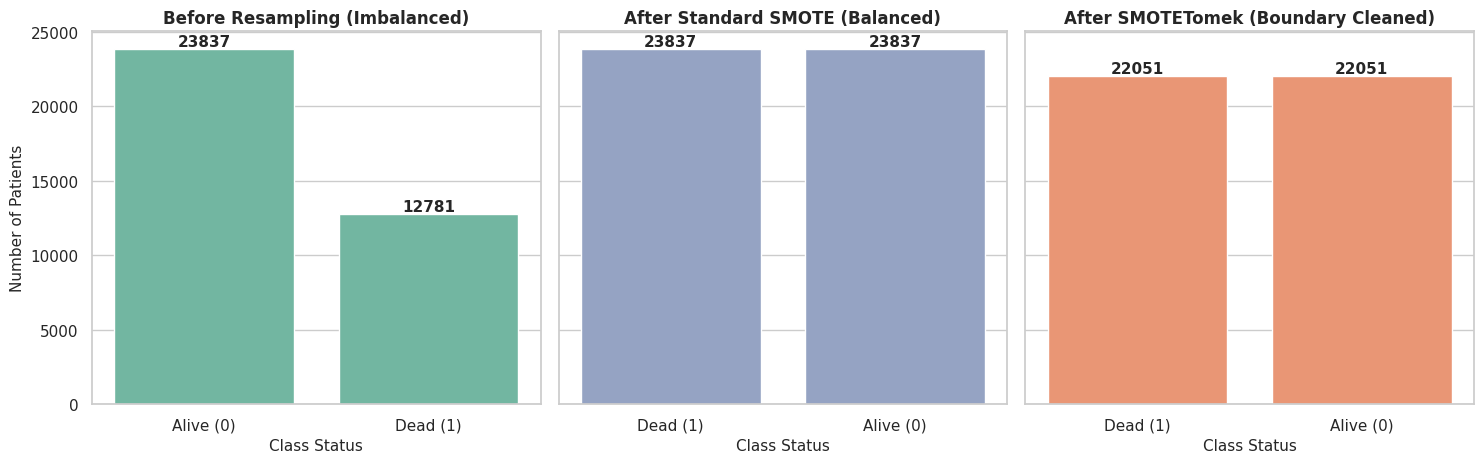

In [10]:
# 1. Thực hiện SMOTE tiêu chuẩn (chỉ trên tập Train)
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print("SMOTE hoàn tất")
# 2. Thực hiện SMOTETomek nâng cao (SMOTE + Lọc nhiễu biên Tomek Links chỉ trên tập Train)
smt = SMOTETomek(random_state=42)
X_train_smotetomek, y_train_smotetomek = smt.fit_resample(X_train, y_train)
print("SMOTETomek hoàn tất")
print(f"Trước khi cân bằng (Original Train): {y_train.value_counts().to_dict()} | Shape: {X_train.shape}")
print(f"Sau khi dùng SMOTE:                  {y_train_smote.value_counts().to_dict()} | Shape: {X_train_smote.shape}")
print(f"Sau khi dùng SMOTETomek:             {y_train_smotetomek.value_counts().to_dict()} | Shape: {X_train_smotetomek.shape}")
print(f"Tập Kiểm thử (Test - Giữ nguyên):    {y_test.value_counts().to_dict()} | Shape: {X_test.shape}")

# Vẽ biểu đồ 3 cột đặt cạnh nhau để đưa vào Slide báo cáo
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)

datasets_plot = [
    (y_train, "Before Resampling (Imbalanced)", '#66c2a5'),
    (y_train_smote, "After Standard SMOTE (Balanced)", '#8da0cb'),
    (y_train_smotetomek, "After SMOTETomek (Boundary Cleaned)", '#fc8d62')
]

for ax, (y_data, title, color) in zip(axes, datasets_plot):
    counts = pd.Series(y_data).map({0: 'Alive (0)', 1: 'Dead (1)'}).value_counts()
    sns.barplot(x=counts.index, y=counts.values, ax=ax, color=color)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Class Status', fontsize=11)
    ax.set_ylabel('Number of Patients', fontsize=11)
    for p in ax.patches:
        ax.annotate(f'{int(p.get_height())}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

In [11]:
assert len(X_test) == len(x_test) == len(y_test), "Tập Test đã bị can thiệp!"
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0, "Có giá trị NaN sau khi tiền xử lý!"
assert list(X_train_smotetomek.columns) == list(X_test.columns), "Cột giữa Train và Test không khớp!"

# Lưu đầy đủ cả 4 phiên bản đồng bộ 18 đặc trưng vào '04 Datasets'
X_train.assign(Status=y_train.values).to_csv(os.path.join(target_dir, 'train_processed_unresampled.csv'), index=False)
X_train_smote.assign(Status=y_train_smote.values).to_csv(os.path.join(target_dir, 'train_processed_smote.csv'), index=False)
X_train_smotetomek.assign(Status=y_train_smotetomek.values).to_csv(os.path.join(target_dir, 'train_processed_smotetomek.csv'), index=False)
X_test.assign(Status=y_test.values).to_csv(os.path.join(target_dir, 'test_processed.csv'), index=False)

print(" ĐÃ LƯU THÀNH CÔNG TẤT CẢ 4 FILE CSV ĐỒNG BỘ VÀO GOOGLE DRIVE:")
print(f"   1. train_processed_unresampled.csv {X_train.shape}")
print(f"   2. train_processed_smote.csv       {X_train_smote.shape}")
print(f"   3. train_processed_smotetomek.csv  {X_train_smotetomek.shape}")
print(f"   4. test_processed.csv              {X_test.shape}")

 ĐÃ LƯU THÀNH CÔNG TẤT CẢ 4 FILE CSV ĐỒNG BỘ VÀO GOOGLE DRIVE:
   1. train_processed_unresampled.csv (36618, 28)
   2. train_processed_smote.csv       (47674, 28)
   3. train_processed_smotetomek.csv  (44102, 28)
   4. test_processed.csv              (6462, 28)


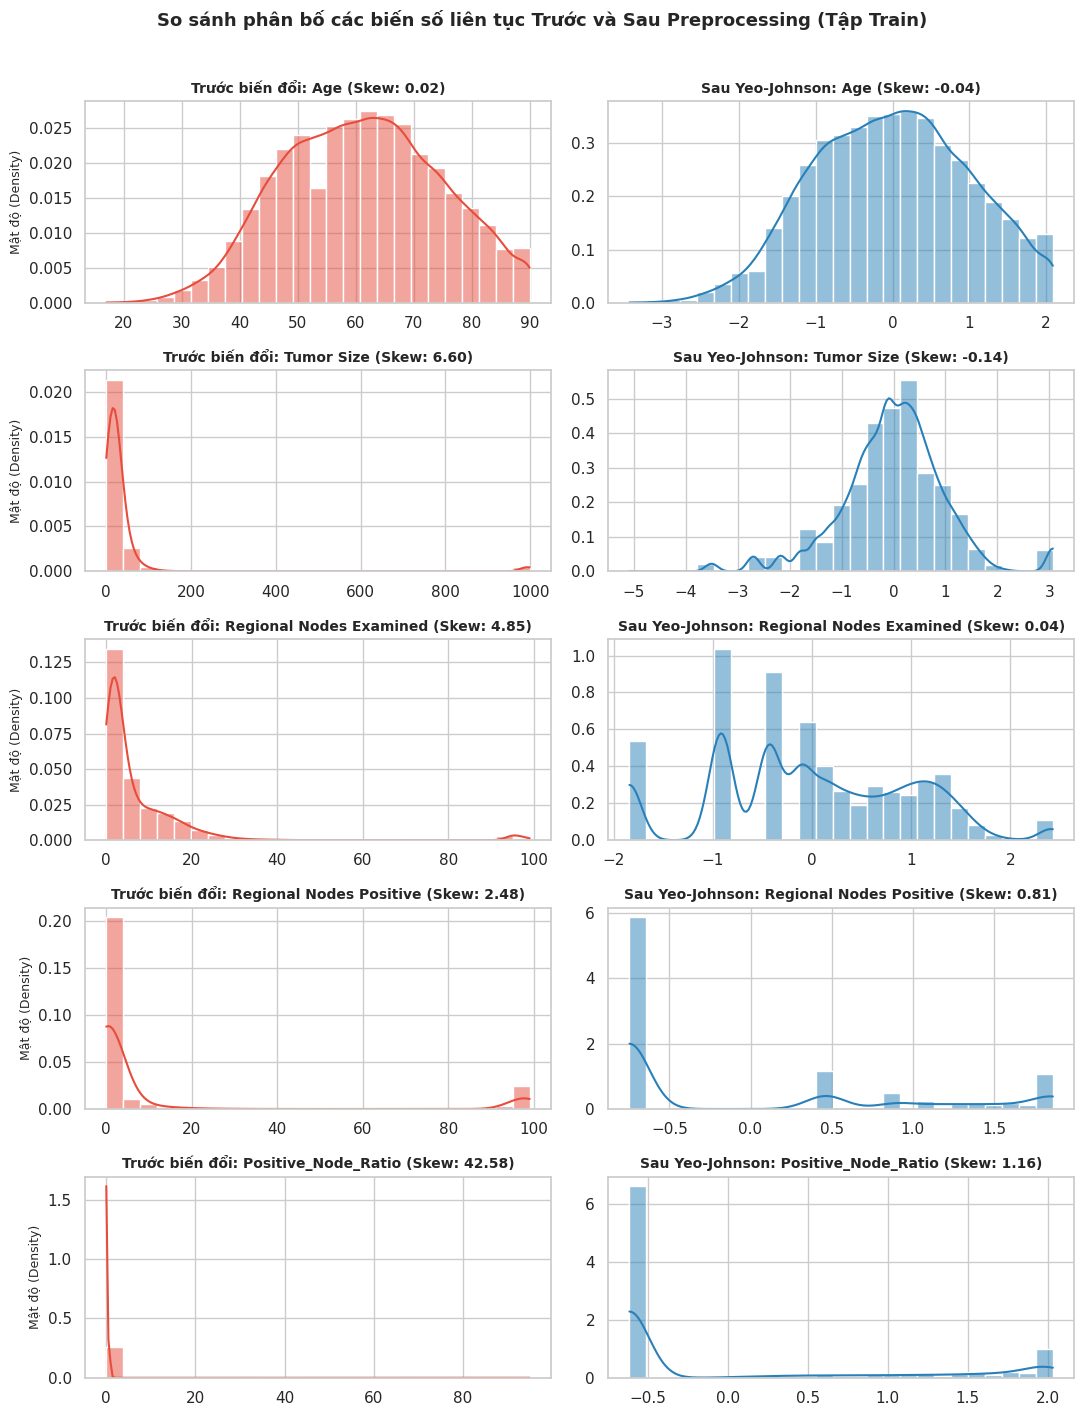

In [12]:
x_train['Tumor Size'] = pd.to_numeric(x_train['Tumor Size'], errors='coerce')
x_train['Tumor Size']=x_train['Tumor Size'].fillna(x_train['Tumor Size'].median())
transformed_num_cols = [
    'num__Age',
    'num__Tumor Size',
    'num__Regional Nodes Examined',
    'num__Regional Nodes Positive',
    'num__Positive_Node_Ratio'
]

fig, axes = plt.subplots(5, 2, figsize=(11, 14))

for idx, (raw_col, trans_col) in enumerate(zip(num_cols, transformed_num_cols)):
    # 1. Cột bên trái: Dữ liệu thô trước khi biến đổi
    sns.histplot(x_train[raw_col], kde=True, ax=axes[idx, 0], color='#e74c3c', bins=25, stat='density')
    axes[idx, 0].set_title(f'Trước biến đổi: {raw_col} (Skew: {x_train[raw_col].skew():.2f})', fontsize=10, fontweight='bold')
    axes[idx, 0].set_ylabel('Mật độ (Density)', fontsize=9)
    axes[idx, 0].set_xlabel('')

    # 2. Cột bên phải: Sau khi biến đổi Yeo-Johnson PowerTransformer
    sns.histplot(X_train[trans_col], kde=True, ax=axes[idx, 1], color='#2980b9', bins=25, stat='density')
    axes[idx, 1].set_title(f'Sau Yeo-Johnson: {raw_col} (Skew: {X_train[trans_col].skew():.2f})', fontsize=10, fontweight='bold')
    axes[idx, 1].set_ylabel('')
    axes[idx, 1].set_xlabel('')

plt.suptitle('So sánh phân bố các biến số liên tục Trước và Sau Preprocessing (Tập Train)', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()

plt.show()

```markdown
## Pipeline Tiền xử lý Y khoa Toàn diện (Biomedical Preprocessing & Patient-Level Zero Data Leakage)
```

In [13]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import PowerTransformer, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler

# 1. Đọc lại dữ liệu gốc và tối ưu kiểu dữ liệu ban đầu để tiết kiệm RAM
raw_data_path = os.path.join(target_dir, 'Breast_Cancer.csv')
df_raw = pd.read_csv(raw_data_path)

# Chuẩn hóa tên cột
df_raw.columns = df_raw.columns.str.strip()
print(f"Kích thước dữ liệu gốc: {df_raw.shape}")

Kích thước dữ liệu gốc: (100000, 17)


In [14]:
# 2. Xử lý chuẩn hóa mã quy ước lâm sàng SEER
# Đưa các giá trị khuyết/không xác định trong y khoa về NaN để xử lý chuẩn hóa
blanks = ['NA', 'Blank(s)', 'TX', 'NX', 'OCCULT', 'UNK Stage', 'Unknown', 'Unknown/Adverse']
df_raw.replace(blanks, np.nan, inplace=True)

# Theo quy ước SEER: Tumor Size >= 990 biểu thị thông tin không xác định hoặc dạng đặc biệt
if 'Tumor Size' in df_raw.columns:
    df_raw['Tumor Size'] = pd.to_numeric(df_raw['Tumor Size'], errors='coerce')
    df_raw.loc[df_raw['Tumor Size'] >= 990, 'Tumor Size'] = np.nan

# Tương tự với Regional Nodes Positive và Examined >= 90 thường là các mã quy ước đặc biệt
if 'Regional Nodes Positive' in df_raw.columns:
    df_raw['Regional Nodes Positive'] = pd.to_numeric(df_raw['Regional Nodes Positive'], errors='coerce')
    df_raw.loc[df_raw['Regional Nodes Positive'] >= 90, 'Regional Nodes Positive'] = np.nan

if 'Regional Nodes Examined' in df_raw.columns:
    df_raw['Regional Nodes Examined'] = pd.to_numeric(df_raw['Regional Nodes Examined'], errors='coerce')
    df_raw.loc[df_raw['Regional Nodes Examined'] >= 90, 'Regional Nodes Examined'] = np.nan

# 3. Tạo biến phái sinh lâm sàng Positive_Node_Ratio (tránh chia cho 0)
if 'Regional Nodes Examined' in df_raw.columns and 'Regional Nodes Positive' in df_raw.columns:
    df_raw['Positive_Node_Ratio'] = np.where(
        df_raw['Regional Nodes Examined'] > 0,
        df_raw['Regional Nodes Positive'] / df_raw['Regional Nodes Examined'],
        0.0
    )

# 4. Mã hóa nhãn mục tiêu Status (Alive = 0, Dead = 1)
if 'Status' in df_raw.columns:
    df_raw['Status'] = df_raw['Status'].str.strip().map({'Alive': 0, 'Dead': 1})

# Loại bỏ dòng bị khuyết nhãn mục tiêu nếu có
df_raw = df_raw.dropna(subset=['Status']).reset_index(drop=True)
df_raw['Status'] = df_raw['Status'].astype('int8')

In [15]:
# 5. Phân tách chống rò rỉ cấp bệnh nhân (Patient-Level Group Split)
# Đảm bảo toàn bộ hồ sơ y tế của cùng một Patient ID chỉ nằm ở một bên tập dữ liệu
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(df_raw, groups=df_raw['Patient ID']))

df_train = df_raw.iloc[train_idx].copy()
df_test = df_raw.iloc[test_idx].copy()

# Kiểm định độc lập lâm sàng nghiêm ngặt
train_patients = set(df_train['Patient ID'])
test_patients = set(df_test['Patient ID'])
assert train_patients.isdisjoint(test_patients), "LỖI RÒ RỈ: Phát hiện cùng bệnh nhân xuất hiện ở cả hai tập Train và Test!"
print(f" Phân tách thành công! Số lượng bệnh nhân độc lập ở tập Train: {len(train_patients)} | Tập Test: {len(test_patients)}")

 Phân tách thành công! Số lượng bệnh nhân độc lập ở tập Train: 79557 | Tập Test: 19890


In [16]:
# 6. Tách đặc trưng X và nhãn y, đồng thời loại bỏ các biến rò rỉ tương lai & định danh
# Loại bỏ 'Survival months' (rò rỉ tương lai) và 'Patient ID' (không có giá trị dự báo)
leakage_cols = ['Patient ID', 'Survival months', 'Status']

X_train_raw = df_train.drop(columns=[col for col in leakage_cols if col in df_train.columns])
y_train = df_train['Status']

X_test_raw = df_test.drop(columns=[col for col in leakage_cols if col in df_test.columns])
y_test = df_test['Status']

# Xác định danh sách các nhóm cột để chuyển đổi
num_cols = ['Age', 'Tumor Size', 'Regional Nodes Examined', 'Regional Nodes Positive', 'Positive_Node_Ratio']
nominal_cols = ['Race', 'Marital status at diagnosis', 'Sequence number', 'A Stage', 'Estrogen Status', 'Progesterone Status']
ordinal_cols = ['T Stage', 'N Stage', '6th Stage', 'Grade']

# Định nghĩa thứ bậc lâm sàng chuẩn cho OrdinalEncoder
ord_cats = [
    ['T0', 'Tis', 'T1', 'T1a', 'T1b', 'T1c', 'T1mic', 'T1NOS', 'T2', 'T3', 'T4', 'T4a', 'T4b', 'T4c', 'T4d', 'T4NOS'],
    ['N0', 'N0(i-)', 'N0(i+)', 'N0(mol-)', 'N0(mol+)', 'N1', 'N1a', 'N1b', 'N1c', 'N1mi', 'N1NOS', 'N2', 'N2a', 'N2b', 'N2NOS', 'N3', 'N3a', 'N3b', 'N3c', 'N3NOS'],
    ['0', 'I', 'II', 'IIA', 'IIB', 'III', 'IIIA', 'IIIB', 'IIIC', 'IIINOS', 'IV'],
    ['I', 'II', 'III', 'IV']
]

# Ép kiểu dữ liệu tối ưu RAM
for col in nominal_cols + ordinal_cols:
    if col in X_train_raw.columns:
        X_train_raw[col] = X_train_raw[col].astype('category')
        X_test_raw[col] = X_test_raw[col].astype('category')

In [17]:
# 7. Thiết lập ColumnTransformer hiệu năng cao
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('transformer', PowerTransformer(method='yeo-johnson', standardize=True))
])

nominal_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])

ordinal_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=ord_cats))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, num_cols),
        ('nominal', nominal_pipeline, nominal_cols),
        ('ordinal', ordinal_pipeline, ordinal_cols)
    ]
).set_output(transform='pandas')

# Áp dụng nguyên tắc Fit-on-Train
X_train_processed = preprocessor.fit_transform(X_train_raw)
X_test_processed = preprocessor.transform(X_test_raw)

# Đảm bảo ép kiểu float32 để tiết kiệm bộ nhớ cho mô hình hóa
X_train_processed = X_train_processed.astype('float32')
X_test_processed = X_test_processed.astype('float32')

print(f"Kích thước ma trận đầu ra tập Train: {X_train_processed.shape}")
print(f"Kích thước ma trận đầu ra tập Test:  {X_test_processed.shape}")

Kích thước ma trận đầu ra tập Train: (79992, 35)
Kích thước ma trận đầu ra tập Test:  (20008, 35)


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [18]:
# 8. Cân bằng mẫu nhẹ nhàng tránh quá tải RAM (Sử dụng RandomUnderSampler)
print("Phân bổ lớp ban đầu tập Train:", y_train.value_counts().to_dict())

# Sử dụng RandomUnderSampler để cân bằng phân bố nhãn nhanh chóng và an toàn về bộ nhớ
rus = RandomUnderSampler(random_state=42)
X_train_resampled, y_train_resampled = rus.fit_resample(X_train_processed, y_train)

print("Phân bổ lớp sau khi lấy mẫu (Under-sampling):", y_train_resampled.value_counts().to_dict())

# 9. Kiểm định chất lượng ma trận đầu ra
assert X_train_resampled.isna().sum().sum() == 0, "Lỗi: Vẫn tồn tại giá trị NaN sau tiền xử lý!"
assert len(X_test_processed) == len(y_test), "Lỗi không đồng bộ kích thước tập Test!"
print("\n Kiểm định thành công: Dữ liệu sạch 100%, sẵn sàng đưa vào huấn luyện các mô hình AI.")

Phân bổ lớp ban đầu tập Train: {0: 53943, 1: 26049}
Phân bổ lớp sau khi lấy mẫu (Under-sampling): {0: 26049, 1: 26049}

 Kiểm định thành công: Dữ liệu sạch 100%, sẵn sàng đưa vào huấn luyện các mô hình AI.
